# 03. Data Preprocessing & Cleaning

## Executive Summary
Data preprocessing transforms messy raw records into a clean, well-formed tabular structure suitable for machine learning.

### Preprocessing Protocol:
1. **Missing Value Resolution:** Audit and impute whitespace values in `TotalCharges`.
2. **Statistical Justification:** Missing values occur exclusively in newly joined customers (`tenure == 0`). Accrued total charges are $0.00.
3. **Identifier Removal:** Drop `customerID` (non-generalizable identifier).
4. **Outlier Validation:** Verify distributions for validity.
5. **Clean Data Export:** Save `data/processed/churn_cleaned.csv`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option("display.max_columns", None)

candidates = [
    Path("../data/raw/Customer_Churn.csv"),
    Path("../data/raw/customer_churn.csv"),
    Path("data/raw/Customer_Churn.csv"),
    Path("data/raw/customer_churn.csv"),
]
raw_path = next((p for p in candidates if p.is_file()), None)
df = pd.read_csv(raw_path)
print(f"Loaded raw dataset with shape: {df.shape}")

Loaded raw dataset with shape: (7043, 21)


## 1. Missing Value and Whitespace Identification

In [2]:
print("Whitespace occurrences in 'TotalCharges':", (df["TotalCharges"] == " ").sum())

# Inspect the records with blank TotalCharges
blank_mask = df["TotalCharges"].str.strip() == ""
df_blank = df[blank_mask]
print(f"Total blank records: {len(df_blank)}")
df_blank[["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

Whitespace occurrences in 'TotalCharges': 11
Total blank records: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


## 2. Type Conversion & Imputation Strategy
We convert `TotalCharges` to float numeric and impute blank entries with 0.0.

In [3]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"].str.strip(), errors="coerce")
print("Null count after coerce:", df["TotalCharges"].isna().sum())

# Impute with 0.0 (since tenure=0)
df["TotalCharges"] = df["TotalCharges"].fillna(0.0)
print("Null count after fillna(0.0):", df["TotalCharges"].isna().sum())

Null count after coerce: 11
Null count after fillna(0.0): 0


## 3. Identifier Removal
`customerID` is a random primary key with 7,043 unique values. Including it would create noise or high-cardinality leakage.

In [4]:
df.drop(columns=["customerID"], inplace=True)
print(f"Shape after dropping customerID: {df.shape}")
df.dtypes

Shape after dropping customerID: (7043, 20)


gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
dtype: object

## 4. Duplicate Check & Outlier Verification

Duplicate rows: 22


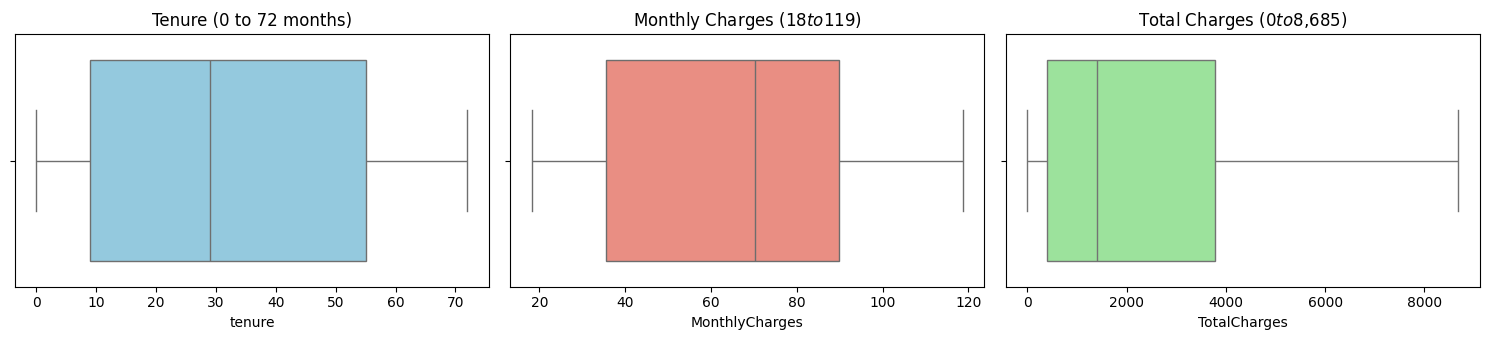

In [5]:
print(f"Duplicate rows: {df.duplicated().sum()}")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
sns.boxplot(x=df["tenure"], ax=axes[0], color="skyblue")
axes[0].set_title("Tenure (0 to 72 months)")

sns.boxplot(x=df["MonthlyCharges"], ax=axes[1], color="salmon")
axes[1].set_title("Monthly Charges ($18 to $119)")

sns.boxplot(x=df["TotalCharges"], ax=axes[2], color="lightgreen")
axes[2].set_title("Total Charges ($0 to $8,685)")

plt.tight_layout()
plt.show()

## 5. Export Cleaned Dataset

In [6]:
out_path = Path("../data/processed/churn_cleaned.csv")
out_path.parent.mkdir(parents=True, exist_ok=True)

df.to_csv(out_path, index=False)
print(f"Cleaned dataset saved successfully to: {out_path.resolve()}")
print(f"Final Cleaned Dataset Dimensions: {df.shape}")

Cleaned dataset saved successfully to: D:\Projects\AIML\data\processed\churn_cleaned.csv
Final Cleaned Dataset Dimensions: (7043, 20)


## Summary Checklist
- [x] Converted `TotalCharges` to numeric float64.
- [x] Imputed 11 zero-tenure blank strings with 0.0.
- [x] Dropped uninformative `customerID` column.
- [x] Verified zero duplicate rows and valid numerical bounds.
- [x] Cleaned dataset serialized to `data/processed/churn_cleaned.csv`.